# Global EDA · NASA FIRMS hot spots (MODIS + VIIRS)
**NASA Space Apps 2026** · Challenge *Harmonization of MODIS and VIIRS Hot Spots*

Data for **every country**: `data/db_nasa.duckdb` (389 M detections, 2000–2025), opened read-only.
Aggregations run inside DuckDB with `q("SELECT …")`, which returns a DataFrame.

In [1]:
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patheffects as pe
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Patch, Rectangle

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.max_rows", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB = ROOT / "data" / "db_nasa.duckdb"
con = duckdb.connect(str(DB), read_only=True)


def q(sql, **params):
    """Run SQL in DuckDB and return a DataFrame. Parameters with $name: q("... = $s", s="MODIS")."""
    return (con.execute(sql, params) if params else con.execute(sql)).df()


print(f"Connected to {DB.relative_to(ROOT)} · {DB.stat().st_size / 1e9:.1f} GB")

Connected to data/db_nasa.duckdb · 6.4 GB


### Chart style
One fixed colour per sensor: **blue = MODIS**, **orange = VIIRS S-NPP**, **aqua = VIIRS NOAA-20**. Magnitudes use a single-hue blue ramp.

In [2]:
SURFACE, INK, INK2, MUTED, GRID, EJE = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
GRIS = "#c9c7bf"  # "the rest" when a single element is highlighted

SENSORES = ["MODIS", "VIIRS_SNPP", "VIIRS_NOAA20"]
VIIRS = ["VIIRS_SNPP", "VIIRS_NOAA20"]
COLOR = {"MODIS": "#2a78d6", "VIIRS_SNPP": "#eb6834", "VIIRS_NOAA20": "#1baf7a"}
NOMBRE = {
    "MODIS": "MODIS (Terra + Aqua)",
    "VIIRS_SNPP": "VIIRS S-NPP",
    "VIIRS_NOAA20": "VIIRS NOAA-20",
}

AZUL = [
    "#cde2fb",
    "#b7d3f6",
    "#9ec5f4",
    "#86b6ef",
    "#6da7ec",
    "#5598e7",
    "#3987e5",
    "#2a78d6",
    "#256abf",
    "#1c5cab",
    "#184f95",
    "#104281",
    "#0d366b",
]
CMAP = LinearSegmentedColormap.from_list("azul", AZUL)
CMAP_MAPA = LinearSegmentedColormap.from_list(
    "azul_mapa", AZUL[3:]
)  # starts darker so a single detection is visible
for c in (CMAP, CMAP_MAPA):
    c.set_bad(SURFACE)
MESES = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec",
]

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "figure.constrained_layout.use": True,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 10,
        "text.color": INK,
        "axes.edgecolor": EJE,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",
        "axes.axisbelow": True,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 10,
        "axes.labelcolor": INK2,
        "axes.labelsize": 9.5,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK2,
        "ytick.labelcolor": INK2,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "lines.linewidth": 2,
        "lines.solid_capstyle": "round",
        "lines.solid_joinstyle": "round",
        "lines.markersize": 6,
        "lines.markeredgewidth": 1.5,
        "lines.markeredgecolor": SURFACE,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "legend.labelcolor": INK2,
    }
)


def _comp(x, d, s):
    return f"{x / d:,.1f}".removesuffix(".0") + s


def compacto(x):
    """1234 -> '1,234' · 12900 -> '12.9K' · 4.2e6 -> '4.2M'."""
    a = abs(x)
    if a >= 1e9:
        return _comp(x, 1e9, "B")
    if a >= 1e6:
        return _comp(x, 1e6, "M")
    if a >= 1e4:
        return _comp(x, 1e3, "K")
    return f"{x:,.0f}"


def eje_numeros(ax, eje="y"):
    """Clean ticks: full numbers below 10,000; compact (10K, 2M) when the axis goes higher."""
    axis = ax.yaxis if eje == "y" else ax.xaxis
    tope = max(abs(v) for v in (ax.get_ylim() if eje == "y" else ax.get_xlim()))
    if tope >= 1e6:
        f = lambda x, _: _comp(x, 1e6, "M") if x else "0"
    elif tope >= 1e4:
        f = lambda x, _: _comp(x, 1e3, "K") if x else "0"
    else:
        f = lambda x, _: f"{x:,.0f}"
    axis.set_major_formatter(mticker.FuncFormatter(f))


def titulo(ax, texto, sub=None):
    """Left-aligned title and, optionally, a grey subtitle below."""
    ax.set_title(texto, pad=22 if sub else 10)
    if sub:
        ax.text(
            0, 1.015, sub, transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom"
        )


def leyenda_sensores(ax, sensores=SENSORES, **kw):
    handles = [plt.Line2D([], [], color=COLOR[s], lw=3) for s in sensores]
    ax.legend(handles, [NOMBRE[s] for s in sensores], **kw)


def etiqueta_final(ax, x, y, texto, dx=6, dy=0):
    ax.annotate(
        texto,
        (x, y),
        xytext=(dx, dy),
        textcoords="offset points",
        va="center",
        color=INK2,
        fontsize=9,
    )


def mapa_aspecto(ax, lat_media):
    ax.set_aspect(1 / np.cos(np.radians(lat_media)))
    ax.grid(False)
    ax.tick_params(labelsize=8)


def barra(fig, mappable, ax, label, **kw):
    """Colorbar with plain numbers (0.1, 1, 10, 100) instead of powers of 10."""
    cb = fig.colorbar(mappable, ax=ax, label=label, **kw)
    if isinstance(mappable.norm, LogNorm):
        cb.ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,g}"))
        cb.ax.yaxis.set_minor_formatter(mticker.NullFormatter())
    cb.outline.set_visible(False)
    return cb


def eje_log(ax, *ejes):
    """Log-axis ticks as plain numbers: 1 · 10 · 100 · 1,000."""
    for e in ejes:
        (ax.xaxis if e == "x" else ax.yaxis).set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"{x:,g}")
        )


CONTORNO = [pe.withStroke(linewidth=3, foreground=SURFACE)]

---
## Global data
- `hotspots`: one row per detection (every country, sensor and year).
- `resumen_mensual`: sensor × country × month, precomputed (detections, vegetation detections, total FRP).
- Views: `modis`, `viirs_snpp`, `viirs_noaa20`, `paises` (countries).

In [3]:
display(
    q(
        "SELECT table_name, table_type FROM information_schema.tables ORDER BY 1"
    )
)
q("DESCRIBE hotspots")[["column_name", "column_type"]]

,table_name,table_type
0,_cargados,BASE TABLE
1,hotspots,BASE TABLE
2,modis,VIEW
3,paises,VIEW
4,resumen_mensual,BASE TABLE
5,viirs_noaa20,VIEW
6,viirs_snpp,VIEW


,column_name,column_type
0,sensor,VARCHAR
1,satellite,VARCHAR
2,country,VARCHAR
3,latitude,DOUBLE
4,longitude,DOUBLE
5,acq_date,DATE
6,acq_time,SMALLINT
7,confidence,VARCHAR
8,bright_mir,FLOAT
9,bright_tir,FLOAT


In [4]:
cobertura = (
    q("""
    SELECT sensor, min(acq_date) AS first_date, max(acq_date) AS last_date,
           count(*) AS detections, count(DISTINCT country) AS countries
    FROM hotspots GROUP BY sensor
""")
    .set_index("sensor")
    .loc[SENSORES]
)
print(f"Total: {cobertura.detections.sum():,} detections")
cobertura

Total: 389,270,053 detections


,first_date,last_date,detections,countries
sensor,,,,
MODIS,2000-11-01,2025-12-31,111424417,233
VIIRS_SNPP,2012-01-20,2017-12-31,121913364,234
VIIRS_NOAA20,2018-04-01,2025-12-31,155932272,234


In [5]:
fullbase = q("""
    SELECT *
    FROM hotspots
    USING SAMPLE 0.05% (bernoulli, 42)
""")
print(
    f"{len(fullbase):,} rows · {fullbase.country.nunique()} countries · {fullbase.acq_date.nunique():,} dates"
)
fullbase

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

195,051 rows · 183 countries · 9,056 dates


,sensor,satellite,country,latitude,longitude,acq_date,acq_time,confidence,bright_mir,bright_tir,scan,track,frp,daynight,type,version
0,MODIS,Terra,Cote d Ivoire,9.51810,-3.69590,2000-12-04,1044,89,340.500000,304.899994,1.60,1.20,71.099998,D,0,6.2
1,MODIS,Terra,Cote d Ivoire,8.68820,-7.12060,2000-12-11,1051,59,311.399994,297.200012,2.10,1.40,18.100000,D,0,6.2
2,MODIS,Terra,Cote d Ivoire,9.77120,-4.92770,2000-12-26,1146,49,321.600006,306.899994,4.00,1.90,54.799999,D,0,6.2
3,MODIS,Terra,Cote d Ivoire,9.84700,-7.06100,2000-12-30,1121,41,319.000000,305.600006,1.10,1.00,6.500000,D,0,6.2
4,MODIS,Terra,Argentina,-35.87370,-67.22650,2000-12-11,318,100,330.600006,295.799988,1.30,1.10,41.400002,N,0,6.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195046,VIIRS_SNPP,N,Zimbabwe,-17.13367,30.35056,2017-11-03,2253,n,300.160004,289.390015,0.56,0.43,1.340000,N,0,2
195047,VIIRS_SNPP,N,Zimbabwe,-18.51142,29.89727,2017-11-04,1124,l,343.570007,314.910004,0.46,0.39,5.380000,D,0,2
195048,VIIRS_SNPP,N,Zimbabwe,-20.52806,28.51524,2017-11-05,1105,n,354.019989,305.750000,0.37,0.58,6.470000,D,0,2
195049,VIIRS_SNPP,N,Zimbabwe,-18.60508,25.96735,2017-11-21,1105,h,367.000000,300.399994,0.52,0.67,49.419998,D,0,2


In [6]:
NOMBRE_SAT = {
    "Terra": "MODIS Terra",
    "Aqua": "MODIS Aqua",
    "N": "VIIRS S-NPP",
    "N20": "VIIRS NOAA-20",
}
COLOR_SAT = {"Terra": "#eda100", "Aqua": "#2a78d6", "N": "#eb6834", "N20": "#1baf7a"}


def grafica_por_satelite(por="year", solo_vegetacion=True):
    """Line chart of the global detections of each satellite.

    por:             "year" or "month"
    solo_vegetacion: True = type 0 only (no volcanoes or industry)
    """
    tiempo = "year(acq_date)" if por == "year" else "date_trunc('month', acq_date)"
    filtro = "WHERE type = 0" if solo_vegetacion else ""
    # by year, drop incomplete years (Terra 2000, Aqua 2002, NOAA-20 2018)
    completos = "HAVING count(DISTINCT month(acq_date)) = 12" if por == "year" else ""
    datos = q(f"""
        SELECT satellite, {tiempo} AS periodo, count(*) AS detecciones
        FROM hotspots
        {filtro}
        GROUP BY satellite, periodo
        {completos}
        ORDER BY periodo
    """)
    tabla = datos.pivot(index="periodo", columns="satellite", values="detecciones")[
        list(NOMBRE_SAT)
    ]

    fig, ax = plt.subplots(figsize=(11, 4.2))
    for sat, nombre in NOMBRE_SAT.items():
        serie = tabla[sat].dropna()
        if por == "year":
            ax.plot(
                serie.index,
                serie.values,
                color=COLOR_SAT[sat],
                marker="o",
                markerfacecolor=COLOR_SAT[sat],
            )
            etiqueta_final(ax, serie.index[-1], serie.values[-1], nombre, dx=8)
        else:  # by month the end labels overlap; the legend is enough
            ax.plot(serie.index, serie.values, color=COLOR_SAT[sat], lw=1.3)
    if por == "year":
        ax.set_xlim(right=2029.5)  # room for the labels
    ax.set_ylim(bottom=0)
    eje_numeros(ax)
    ax.set_ylabel(f"detections per {por}")
    ax.legend(
        [plt.Line2D([], [], color=COLOR_SAT[s], lw=3) for s in NOMBRE_SAT],
        NOMBRE_SAT.values(),
        loc="upper left",
    )
    titulo(
        ax,
        f"Fire detections by satellite, per {por} (whole world)",
        ("Vegetation only (type = 0)" if solo_vegetacion else "All sources")
        + (" · complete years" if por == "year" else ""),
    )
    plt.show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

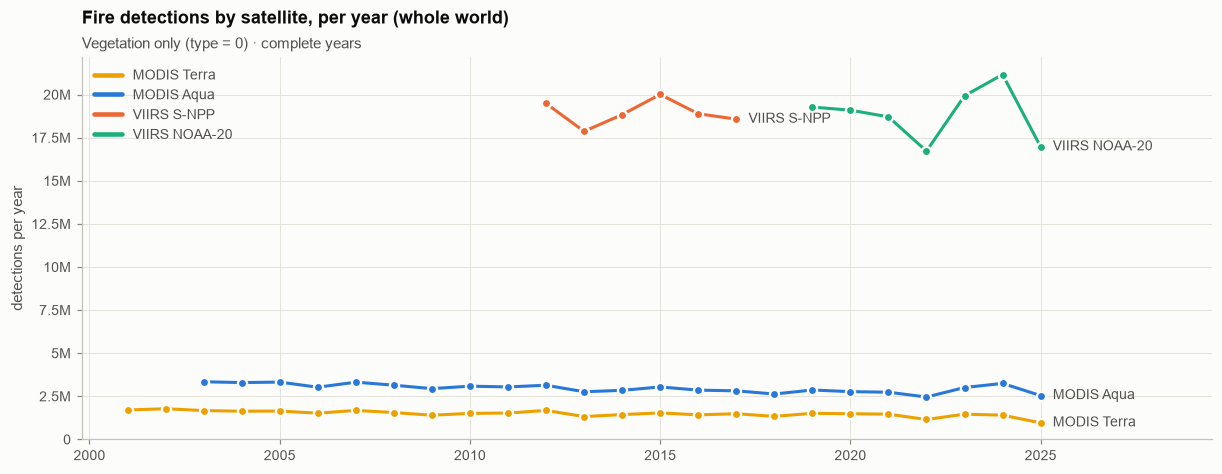

In [7]:
grafica_por_satelite()

In [8]:
def mapa_calor_satelites(solo_vegetacion=True):
    """Is the yearly fire cycle the same on every satellite?

    Each cell = % of that satellite's detections in that year that fell in that month
    (each satellite-year adds up to 100 %). This removes the difference in level between
    satellites, so all of them share one colour scale.

    Rows = months. Columns = years; inside each year, fixed positions:
    T = Terra · A = Aqua · V = VIIRS (S-NPP until 2017, NOAA-20 from 2019).
    At the end, the average of all years with the % written in.
    Only complete years (12 months) of each satellite.
    Returns the table (satellite, year, month, detections, pct).
    """
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import TwoSlopeNorm

    datos = q(f"""
        SELECT satellite, year(acq_date) AS anio, month(acq_date) AS mes, count(*) AS detecciones
        FROM hotspots
        {"WHERE type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    datos["pos"] = datos.satellite.map(
        {"Terra": "T", "Aqua": "A", "N": "V", "N20": "V"}
    )
    completos = datos.groupby(["satellite", "anio"]).mes.transform("nunique") == 12
    datos = datos[completos].copy()
    datos["pct"] = (
        datos.detecciones
        / datos.groupby(["satellite", "anio"]).detecciones.transform("sum")
        * 100
    )
    datos = datos.sort_values(["anio", "pos", "mes"]).reset_index(drop=True)

    POSICIONES = ["T", "A", "V"]
    TIPICO = 100 / 12  # if fire were spread evenly, each month would have 8.3 %
    # Diverging: red = more fire than a typical month, blue = less, grey = normal
    cmap = LinearSegmentedColormap.from_list(
        "mes_tipico", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#b8302f"]
    )
    norm = TwoSlopeNorm(vcenter=TIPICO, vmin=datos.pct.min(), vmax=datos.pct.max())
    HUECO = 0.5

    fig, ax = plt.subplots(figsize=(14, 6.6))
    x, centros, etiquetas = 0.0, [], []
    for anio in sorted(datos.anio.unique()):
        x0 = x
        for pos in POSICIONES:
            d = datos[(datos.pos == pos) & (datos.anio == anio)]
            if not d.empty:
                valores = d.set_index("mes").pct.reindex(range(1, 13)).values
                ax.imshow(
                    cmap(norm(valores))[:, None, :],
                    extent=(x + 0.05, x + 0.95, 12.5, 0.5),
                    aspect="auto",
                    interpolation="nearest",
                )
            ax.text(
                x + 0.5, 0.35, pos, ha="center", va="bottom", fontsize=6.5, color=MUTED
            )
            x += 1
        centros.append((x0 + x) / 2)
        etiquetas.append(str(anio))
        x += HUECO

    # Final block: average of all years, with the % written in
    x += 1.0
    x0, ancho = x, 1.7
    prom = datos.groupby(["pos", "mes"]).pct.mean().unstack(0)[POSICIONES]
    for pos in POSICIONES:
        valores = prom[pos].values
        ax.imshow(
            cmap(norm(valores))[:, None, :],
            extent=(x + 0.05, x + ancho - 0.05, 12.5, 0.5),
            aspect="auto",
            interpolation="nearest",
        )
        for mes, v in enumerate(valores, 1):
            ax.text(
                x + ancho / 2,
                mes,
                f"{v:.0f}%",
                ha="center",
                va="center",
                fontsize=7.5,
                color="white" if abs(norm(v) - 0.5) > 0.3 else INK,
            )
        ax.text(
            x + ancho / 2,
            0.35,
            pos,
            ha="center",
            va="bottom",
            fontsize=6.5,
            color=MUTED,
        )
        x += ancho
    centros.append((x0 + x) / 2)
    etiquetas.append("Average")

    ax.set_xlim(-HUECO, x + 0.2)
    ax.set_ylim(12.5, -0.3)
    ax.set_yticks(range(1, 13), MESES, fontsize=9)
    ax.set_xticks(centros, etiquetas, fontsize=8, rotation=90)
    ax.get_xticklabels()[-1].set_fontweight("bold")
    ax.tick_params(length=0)
    ax.grid(False)
    for lado in ("top", "right", "bottom", "left"):
        ax.spines[lado].set_visible(False)

    cb = fig.colorbar(
        ScalarMappable(norm=norm, cmap=cmap),
        ax=ax,
        orientation="horizontal",
        shrink=0.45,
        pad=0.02,
        aspect=35,
        label="% of the year's detections in that month · red = more fire than a typical month, blue = less",
    )
    marcas = sorted(
        [
            v
            for v in range(2, int(datos.pct.max()) + 1, 2)
            if norm.vmin <= v <= norm.vmax and abs(v - TIPICO) > 1
        ]
        + [TIPICO]
    )
    cb.set_ticks(marcas)
    cb.ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda v, _: "8.3%\ntypical month" if abs(v - TIPICO) < 0.01 else f"{v:.0f}%"
        )
    )
    cb.ax.tick_params(labelsize=8)
    cb.outline.set_visible(False)

    titulo(
        ax,
        "The yearly fire cycle is the same on every satellite",
        "In each year: T = Terra · A = Aqua · V = VIIRS (S-NPP 2012–17, NOAA-20 2019–25)"
        " · blank: the satellite was not operating or the year is incomplete"
        + (" · vegetation only" if solo_vegetacion else ""),
    )
    plt.show()
    return datos.rename(columns={"anio": "year", "mes": "month", "detecciones": "detections"})

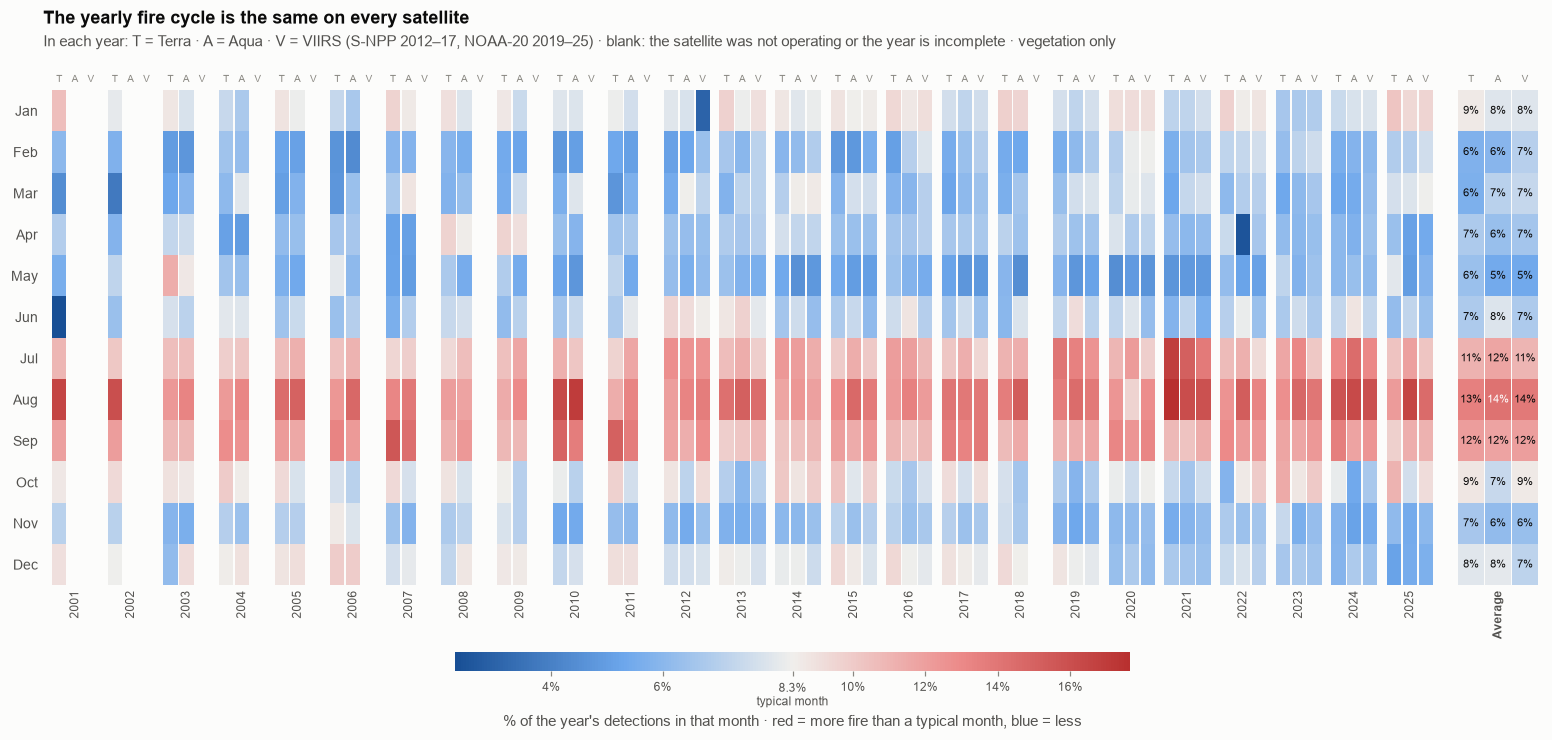

,satellite,year,month,detections,pos,pct
0,Terra,2001,1,179955,T,10.539450
1,Terra,2001,2,103244,T,6.046706
2,Terra,2001,3,75844,T,4.441966
3,Terra,2001,4,118454,T,6.937512
4,Terra,2001,5,95754,T,5.608038
...,...,...,...,...,...,...
727,N20,2025,8,2465120,V,14.522452
728,N20,2025,9,1895027,V,11.163935
729,N20,2025,10,1560991,V,9.196070
730,N20,2025,11,1026035,V,6.044551


In [9]:
mapa_calor_satelites()

In [10]:
def cajas(ax, grupos, posiciones, color, ancho=0.6, horizontal=False):
    """Box-and-whisker plot: box = middle 50 % of the values, white line = median,
    whiskers = normal range (up to 1.5 times the box height), dots = outliers."""
    ax.boxplot(
        grupos,
        positions=posiciones,
        widths=ancho,
        patch_artist=True,
        manage_ticks=False,
        orientation="horizontal" if horizontal else "vertical",
        boxprops=dict(facecolor=color, edgecolor=color),
        medianprops=dict(color=SURFACE, lw=2),
        whiskerprops=dict(color=color, lw=1.5),
        capprops=dict(color=color, lw=1.5),
        flierprops=dict(
            marker="o",
            markersize=3,
            markerfacecolor=color,
            markeredgecolor="none",
            alpha=0.4,
        ),
    )


def conteo_por_satelite(desde="2012-01-20", solo_vegetacion=False):
    """How many hot spots does each satellite detect per day, and how much does it vary from day to day?

    Each satellite operated in different years, so the totals are not comparable.
    It compares the average detections per day with data, from the same date for all of them
    (by default since VIIRS exists: 20 Jan 2012).
    """
    diario = q(f"""
        SELECT satellite, acq_date, count(*) AS detecciones
        FROM hotspots
        WHERE acq_date >= DATE '{desde}' {"AND type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    g = diario.groupby("satellite").detecciones
    datos = pd.DataFrame(
        {
            "desde": diario.groupby("satellite").acq_date.min(),
            "hasta": diario.groupby("satellite").acq_date.max(),
            "dias": g.size(),
            "detecciones": g.sum(),
            "por_dia": g.mean(),
            "p25": g.quantile(0.25),
            "mediana": g.median(),
            "p75": g.quantile(0.75),
        }
    ).loc[list(NOMBRE_SAT)]
    datos["veces_terra"] = datos.por_dia / datos.por_dia["Terra"]
    datos["veces_aqua"] = datos.por_dia / datos.por_dia["Aqua"]

    fig, (ax, ax2) = plt.subplots(
        1, 2, figsize=(14, 3.9), sharey=True, width_ratios=[1.15, 1]
    )
    y = np.arange(len(datos))[::-1]

    # Left: average per day
    ax.barh(y, datos.por_dia, color=[COLOR_SAT[s] for s in datos.index], height=0.6)
    for yi, (s, f) in zip(y, datos.iterrows()):
        ax.text(
            f.por_dia + datos.por_dia.max() * 0.01,
            yi,
            f"  {compacto(f.por_dia)} · "
            + ("reference" if s == "Terra" else f"{f.veces_terra:.1f}× Terra"),
            va="center",
            fontsize=10,
            color=INK,
        )
    ax.set_yticks(y, [NOMBRE_SAT[s] for s in datos.index])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, datos.por_dia.max() * 1.45)
    eje_numeros(ax, "x")
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("average detections per day")
    titulo(
        ax,
        "Average per day",
        f"Global since {desde} · "
        + (
            "vegetation only"
            if solo_vegetacion
            else "all types (vegetation, volcanoes, industry, water)"
        ),
    )

    # Right: day-to-day spread
    for yi, s in zip(y, datos.index):
        cajas(
            ax2,
            [diario.detecciones[diario.satellite == s]],
            [yi],
            COLOR_SAT[s],
            horizontal=True,
        )
    ax2.set_xlim(left=0)
    eje_numeros(ax2, "x")
    ax2.grid(axis="y", visible=False)
    ax2.tick_params(axis="y", length=0)
    ax2.set_xlabel("detections in one day")
    titulo(
        ax2,
        "How much does it vary from day to day?",
        "Box = middle 50 % of days · white line = median · dots = unusual days",
    )

    viirs = datos[datos.index.isin(["N", "N20"])]
    fig.suptitle(
        f"VIIRS detects ~{viirs.veces_terra.mean():.0f} times more hot spots than MODIS Terra "
        f"and ~{viirs.veces_aqua.mean():.0f} times more than Aqua",
        x=0.01,
        ha="left",
        fontweight="bold",
        fontsize=13,
    )
    plt.show()

    return datos.rename(
        columns={
            "desde": "from",
            "hasta": "to",
            "dias": "days",
            "detecciones": "detections",
            "por_dia": "average per day",
            "mediana": "median",
            "veces_terra": "× Terra",
            "veces_aqua": "× Aqua",
        }
    ).round(
        {
            "average per day": 0,
            "p25": 0,
            "median": 0,
            "p75": 0,
            "× Terra": 1,
            "× Aqua": 1,
        }
    )

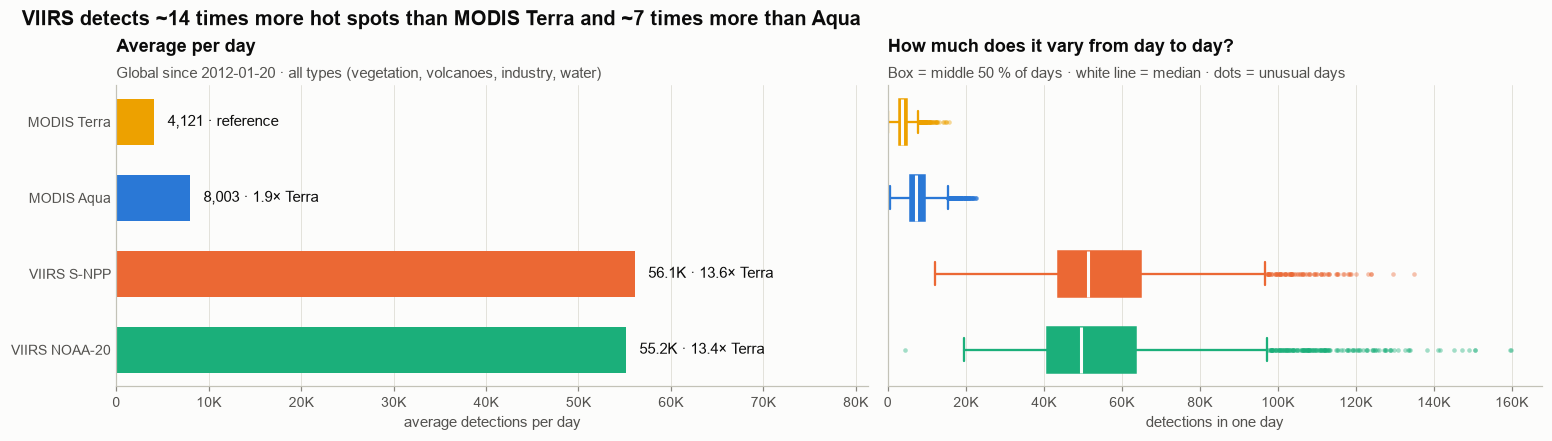

,from,to,days,detections,average per day,p25,median,p75,× Terra,× Aqua
satellite,,,,,,,,,,
Terra,2012-01-20,2025-12-31,5074,20911048,4121.0,2941.0,3723.0,4912.0,1.0,0.5
Aqua,2012-01-20,2025-12-31,5079,40648658,8003.0,5605.0,7159.0,9561.0,1.9,1.0
N,2012-01-20,2017-12-31,2172,121913364,56130.0,43602.0,51459.0,65013.0,13.6,7.0
N20,2018-04-01,2025-12-31,2826,155932272,55178.0,40874.0,49432.0,63528.0,13.4,6.9


In [11]:
conteo_por_satelite()

In [12]:
def promedio_mensual(referencia="Aqua", desde="2012-01-01", solo_vegetacion=False):
    """Average detections per month on one satellite, and how many times more (or fewer) the others detect.
    Then the same as box plots, to see how much it changes from one year to the next.

    referencia:      "Terra", "Aqua", "N" (S-NPP) or "N20" (NOAA-20)
    desde:           only uses months from this date (2012 = VIIRS already existed)
    solo_vegetacion: False = every detection type
    Only complete months are counted (no days without data), for a fair comparison.
    """
    datos = q(f"""
        SELECT satellite, year(acq_date) AS año, month(acq_date) AS mes,
               count(*) AS detecciones, count(DISTINCT acq_date) AS dias
        FROM hotspots
        WHERE acq_date >= DATE '{desde}' {"AND type = 0" if solo_vegetacion else ""}
        GROUP BY ALL
    """)
    dias_del_mes = pd.to_datetime(
        dict(year=datos.año, month=datos.mes, day=1)
    ).dt.days_in_month
    datos = datos[datos.dias == dias_del_mes]
    tabla = datos.pivot(index=["año", "mes"], columns="satellite", values="detecciones")

    # 1) average of each month of the year, per satellite
    promedio = tabla.groupby(level="mes").mean().reindex(columns=list(NOMBRE_SAT))
    # 2) how many times the reference: only months (same month and year) in which both have data
    otros = [
        s
        for s in NOMBRE_SAT
        if s != referencia and not tabla[[referencia, s]].dropna().empty
    ]
    razon, veces, veces_total = {}, {}, {}
    for s in otros:
        par = tabla[[referencia, s]].dropna()
        razon[s] = par[s] / par[referencia]  # one value per month-year
        suma = par.groupby(level="mes").sum()
        veces[s] = suma[s] / suma[referencia]
        veces_total[s] = par[s].sum() / par[referencia].sum()
    veces = pd.DataFrame(veces)

    x = np.arange(1, 13)
    ancho = 0.8 / len(otros)
    posicion = {s: x - 0.4 + ancho * (k + 0.5) for k, s in enumerate(otros)}
    años = tabla[referencia].dropna().index.get_level_values("año")
    alcance = f"{años.min()}–{años.max()} · global · " + (
        "vegetation only" if solo_vegetacion else "all types"
    )
    linea_ref = plt.Line2D([], [], color=INK2, lw=1)

    def ejes_comunes(ax_arriba, ax_abajo):
        eje_numeros(ax_arriba, "y")
        ax_arriba.grid(axis="x", visible=False)
        ax_arriba.tick_params(labelbottom=True)
        ax_abajo.axhline(1, color=INK2, lw=1)
        ax_abajo.yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda v, _: f"{v:g}×")
        )
        ax_abajo.grid(axis="x", visible=False)
        ax_abajo.set_xticks(x, MESES)

    # ── Figure 1: bars with the average ──
    fig, (ax1, ax2) = plt.subplots(
        2, 1, figsize=(12, 8.5), sharex=True, height_ratios=[1, 1.2]
    )
    ref = promedio[referencia]
    ax1.bar(x, ref, width=0.7, color=COLOR_SAT[referencia])
    for m, v in ref.items():
        ax1.text(m, v, compacto(v), ha="center", va="bottom", fontsize=9, color=INK2)
    ax1.set_ylim(0, ref.max() * 1.15)
    titulo(
        ax1,
        f"{NOMBRE_SAT[referencia]}: average detections per month",
        f"Average of each month, {alcance}",
    )
    for s in otros:
        ax2.bar(
            posicion[s],
            veces[s],
            width=ancho,
            color=COLOR_SAT[s],
            edgecolor=SURFACE,
            linewidth=1,
        )
    ax2.set_ylim(0, veces.max().max() * 1.2)
    ax2.legend(
        [linea_ref] + [Patch(color=COLOR_SAT[s]) for s in otros],
        [f"{NOMBRE_SAT[referencia]} = 1×"]
        + [f"{NOMBRE_SAT[s]} · {veces_total[s]:.1f}× on average" for s in otros],
        loc="upper left",
        ncol=len(otros) + 1,
        frameon=False,
    )
    titulo(
        ax2,
        f"The other satellites: how many times what {NOMBRE_SAT[referencia]} detects?",
        "Comparing the same month of the same year · line = same as the reference",
    )
    ejes_comunes(ax1, ax2)
    plt.show()

    # ── Figure 2: box plots, each year is one value ──
    fig, (ax3, ax4) = plt.subplots(
        2, 1, figsize=(12, 8.5), sharex=True, height_ratios=[1, 1.2]
    )
    por_mes = tabla[referencia].dropna().groupby(level="mes")
    cajas(
        ax3,
        [g.to_numpy() for _, g in por_mes],
        [m for m, _ in por_mes],
        COLOR_SAT[referencia],
        ancho=0.6,
    )
    ax3.set_ylim(bottom=0)
    titulo(
        ax3,
        f"{NOMBRE_SAT[referencia]}: how much does each month change from year to year?",
        f"Each year is one value ({alcance}) · box = middle 50 % · white line = median · dots = unusual years",
    )
    for s in otros:
        por_mes = razon[s].groupby(level="mes")
        cajas(
            ax4,
            [g.to_numpy() for _, g in por_mes],
            posicion[s][[m - 1 for m, _ in por_mes]],
            COLOR_SAT[s],
            ancho=ancho * 0.85,
        )
    ax4.set_ylim(0, max(r.max() for r in razon.values()) * 1.15)
    ax4.legend(
        [linea_ref] + [Patch(color=COLOR_SAT[s]) for s in otros],
        [f"{NOMBRE_SAT[referencia]} = 1×"] + [NOMBRE_SAT[s] for s in otros],
        loc="upper left",
        ncol=len(otros) + 1,
        frameon=False,
    )
    titulo(
        ax4,
        f"The other satellites as multiples of {NOMBRE_SAT[referencia]}: is the difference stable from year to year?",
        "Each box gathers the same month of every year in which both satellites have data",
    )
    ejes_comunes(ax3, ax4)
    plt.show()

    resultado = pd.concat(
        {
            "average per month": promedio.round(0),
            f"× {NOMBRE_SAT[referencia]}": veces.round(2),
        },
        axis=1,
    )
    resultado = resultado.rename(columns=NOMBRE_SAT, level=1)
    resultado.index = MESES
    return resultado

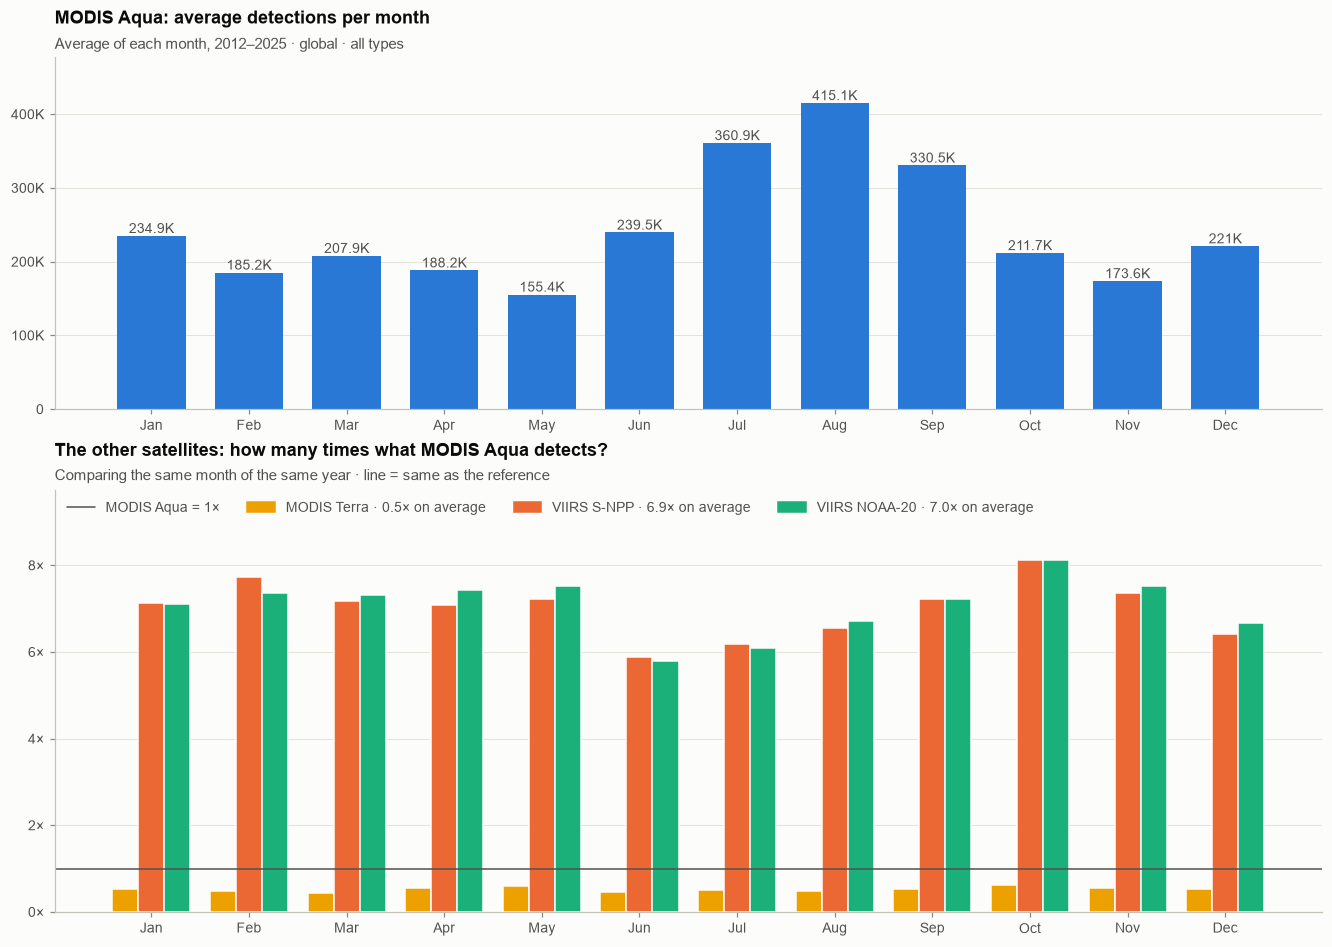

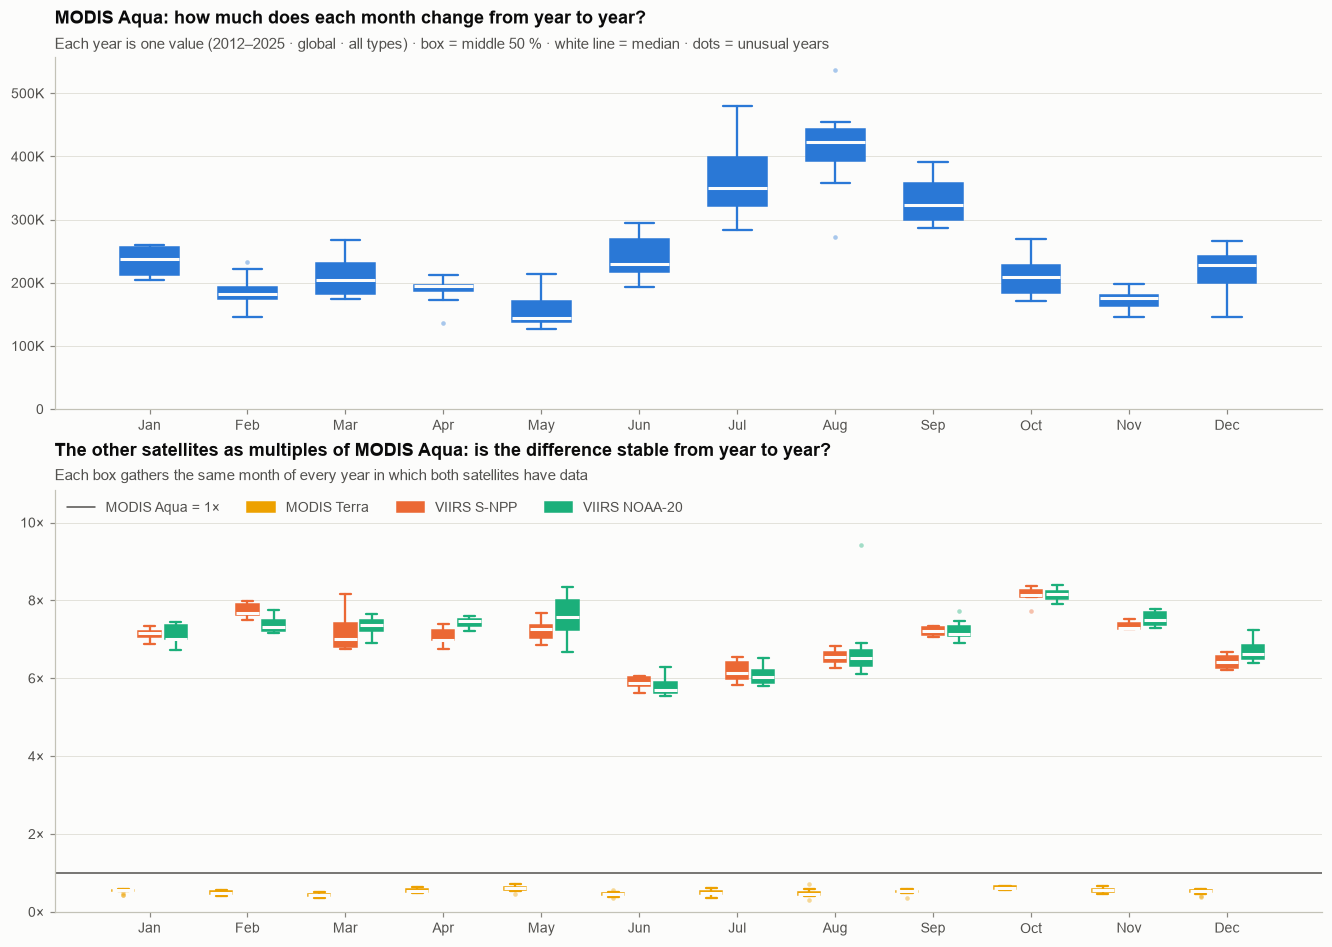

average per month                                      × MODIS Aqua                          
          MODIS Terra MODIS Aqua VIIRS S-NPP VIIRS NOAA-20  MODIS Terra VIIRS S-NPP VIIRS NOAA-20
Jan          125496.0   234907.0   1685060.0     1626744.0         0.53        7.12          7.12
Feb           89016.0   185195.0   1370649.0     1455340.0         0.48        7.73          7.36
Mar           91000.0   207888.0   1488854.0     1488811.0         0.44        7.17          7.32
Apr          102896.0   188182.0   1403304.0     1318637.0         0.55        7.07          7.43
May           92167.0   155395.0   1147183.0     1148527.0         0.59        7.21          7.52
Jun          109721.0   239534.0   1469305.0     1345113.0         0.46        5.88          5.80
Jul          178252.0   360868.0   2166122.0     2220551.0         0.49        6.19          6.10
Aug          199026.0   415120.0   2667968.0     2820146.0         0.48        6.54          6.70
Sep          172612.0   330534.0   2391802.0     2352998.0         0.52        7.21          7.23
Oct          132302.0   211736.0   1798159.0     1660808.0         0.63        8.12          8.12
Nov           97282.0   173647.0   1331696.0     1263660.0         0.56        7.35          7.52
Dec          115601.0   220972.0   1573890.0     1354300.0         0.52        6.42          6.67

In [13]:
promedio_mensual()